# Study 1, notebook 4: the 2D flux upper limit

A realisation draws a position in the ROI (a bin with probability ~ p_b, uniform inside the bin;
with several fields a HEALPix pixel of the 95% region inside some field's ROI), injects a power law
of index 2 with amplitude phi0 at 1 TeV, Poisson-fakes the counts and computes Lambda. The limit is the
phi0 at which P(Lambda > Lambda*) = CL = 0.95. The detection fraction is fitted with a probit curve
in log phi0 (floor fixed by the background, free ceiling), on realisations placed adaptively around
the crossing (`ulfit.adaptive_fit`). The Monte Carlo uncertainty of the limit is the 1 sigma profile
interval of log10 phi0_UL.

Closure: an independent sample simulated at phi0_UL must give a detection fraction of 0.95 within
its binomial error combined with the uncertainty of the limit.

Inputs: the case; caches `realisations_fields` (background, fit batches, closure). The budget is
`flux_ul.DEFAULTS` (a few hundred realisations per round, at most `max_sims` in the fit); larger
budgets go through `scripts/run_flux_ul.py`.

In [1]:
CASE = "sim_wobble"   # case name in configs/cases/

Imports, figure saver and the budget used.

In [2]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt

from uuls import flux_ul, realisations
from uuls.figures import FigureSaver, COLORS

figs = FigureSaver("1_flux_ul", "4_flux_ul")
N_JOBS = 2
print(flux_ul.DEFAULTS)

{'cl': 0.95, 'index': 2.0, 'x_lo': 1e-13, 'x_hi': 3e-10, 'n_bkg': 1000, 'n_scout': 300, 'n_refine': 500, 'max_sims': 1500, 'precision': 0.03, 'n_closure': 300, 'seed': 0, 'correlation_radius_deg': 0.1, 'roi': 'observed', 'production': '2025_2p5'}


The whole limit through `flux_ul.flux_ul`. Background and data come from the cache filled by
notebooks 2 and 3; the fit rounds and the closure sample are computed on the first run and cached.
The result is also written to `outputs/results/1_flux_ul/<CASE>.json`.

In [3]:
res, det = flux_ul.flux_ul(CASE, n_jobs=N_JOBS, details=True)
ul = det["ul"]
print(ul.report("phi0", "cm-2 s-1 TeV-1"))

[cache] gwmap/7a469d1cf166: loaded


[cache] realisations_fields/923496b479ca: loaded


[  scout] N =   300, total 300, fit on 300: phi0_UL = 2.2910e-12 cm-2 s-1 TeV-1 [2.0072e-12, 2.7312e-12] (+-0.0669 dex), width 0.129 dex, f0 0.501, c 1.0000


[round 1] N =   500, total 800, fit on 725: phi0_UL = 2.4308e-12 cm-2 s-1 TeV-1 [2.2816e-12, 2.6164e-12] (+-0.0297 dex), width 0.185 dex, f0 0.499, c 1.0000
[cache] realisations_fields/1cec93abaf92: loaded
phi0_UL = 2.4308e-12 cm-2 s-1 TeV-1  (CL 0.95, target Lambda -4.091)
  1 sigma    -6.1% /   +7.6%   [2.282e-12, 2.616e-12] cm-2 s-1 TeV-1
  2 sigma   -11.4% /  +17.3%   [2.154e-12, 2.852e-12] cm-2 s-1 TeV-1
  width 0.185 +- 0.025 dex, f0 0.499 +- 0.016 (background only 0.500), ceiling 1.0000 +- 0.0000
  goodness of fit chi2/ndof = 2.5/5 (p = 0.78); 2 round(s), 800 realisations, converged True


The limit as amplitude, photon flux and energy flux in 0.6-20 TeV (index 2), with the 1 sigma Monte
Carlo interval. The limit holds for a source inside the ROI, which carries the printed GW probability.

In [4]:
print(f"case {res['case']}, {res['n_fields']} field(s), ROI GW probability {res['roi_gw_prob']:.3f}")
print(f"Lambda_obs = {res['lambda_obs']:.3f}, p = {res['background']['p_value']:.3f}, target = {res['target']:.3f}")
for key, label in (("amplitude", "phi0 at 1 TeV"), ("photon_flux", "photon flux 0.6-20 TeV"),
                   ("energy_flux", "energy flux 0.6-20 TeV")):
    d = res[key]
    print(f"{label:24s} UL = {d['ul']:.3e}  1 sigma [{d['lo_1sigma']:.3e}, {d['hi_1sigma']:.3e}]  {d['unit']}")
print(f"MC uncertainty of log10 UL: +-{res['log10_ul_err_dex']:.3f} dex "
      f"({100 * (10 ** res['log10_ul_err_dex'] - 1):.1f}%)")

case sim_wobble, 1 field(s), ROI GW probability 0.947
Lambda_obs = -5.456, p = 0.727, target = -4.091
phi0 at 1 TeV            UL = 2.431e-12  1 sigma [2.282e-12, 2.616e-12]  cm-2 s-1 TeV-1 at 1 TeV
photon flux 0.6-20 TeV   UL = 3.930e-12  1 sigma [3.689e-12, 4.230e-12]  cm-2 s-1
energy flux 0.6-20 TeV   UL = 1.366e-11  1 sigma [1.282e-11, 1.470e-11]  erg cm-2 s-1
MC uncertainty of log10 UL: +-0.030 dex (7.1%)


Detection fraction against phi0: binned realisations, the fitted probit with its 1 and 2 sigma bands,
and the limit. Below, Lambda of every realisation used, by round.

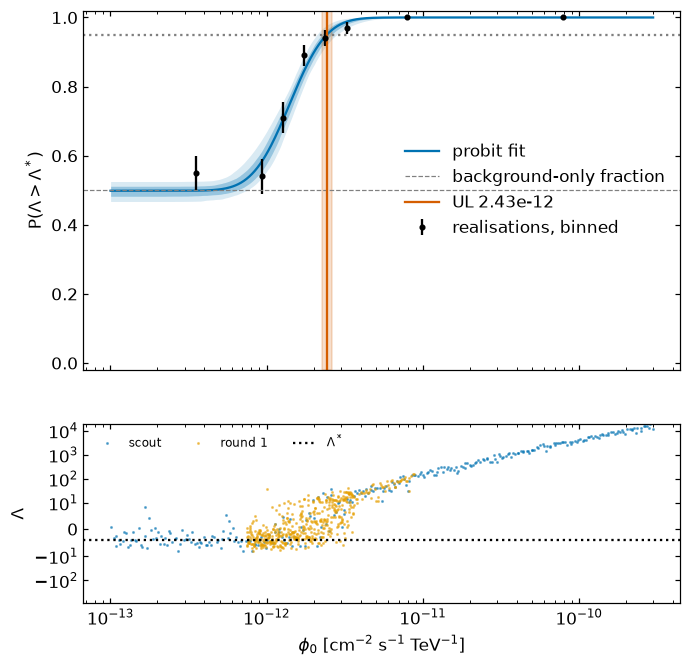

In [5]:
c, b = ul.curve, ul.binned
fig, axs = plt.subplots(2, 1, figsize=(7, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axs[0]
if "p_lo_2sigma" in c:
    ax.fill_between(c["x"], c["p_lo_2sigma"], c["p_hi_2sigma"], color=COLORS[0], alpha=0.15, lw=0)
    ax.fill_between(c["x"], c["p_lo_1sigma"], c["p_hi_1sigma"], color=COLORS[0], alpha=0.3, lw=0)
ax.plot(c["x"], c["p"], color=COLORS[0], label="probit fit")
ax.errorbar(b["x"], b["frac"], yerr=b["err"], fmt="o", ms=3, color="k", label="realisations, binned")
ax.axhline(ul.cl, color="0.5", ls=":")
ax.axhline(ul.f0_bkg, color="0.5", ls="--", lw=0.8, label="background-only fraction")
ax.axvline(ul.x_ul, color=COLORS[3], label=f"UL {ul.x_ul:.2e}")
ax.axvspan(ul.x_ul_lo_1sigma, ul.x_ul_hi_1sigma, color=COLORS[3], alpha=0.2)
ax.set_ylabel(r"P($\Lambda > \Lambda^*$)")
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="center right")
s = ul.samples
for r in np.unique(s["round"]):
    m = s["round"] == r
    axs[1].plot(s["x"][m], s["lambda"][m], ".", ms=2, alpha=0.5, label="scout" if r == 0 else f"round {r}")
axs[1].axhline(ul.target, color="k", ls=":", label=r"$\Lambda^*$")
axs[1].set_xscale("log")
axs[1].set_yscale("symlog", linthresh=10)
axs[1].set_xlabel(r"$\phi_0$ [cm$^{-2}$ s$^{-1}$ TeV$^{-1}$]")
axs[1].set_ylabel(r"$\Lambda$")
axs[1].legend(fontsize=8, ncol=3)
figs.save(fig, "ul_fit")
plt.show()

Fit diagnostics: the profile of -2 ln L in log10 phi0_UL (the 1 and 2 sigma intervals are where it
crosses 1 and 4) and the pulls of the binned detection fraction about the fit.

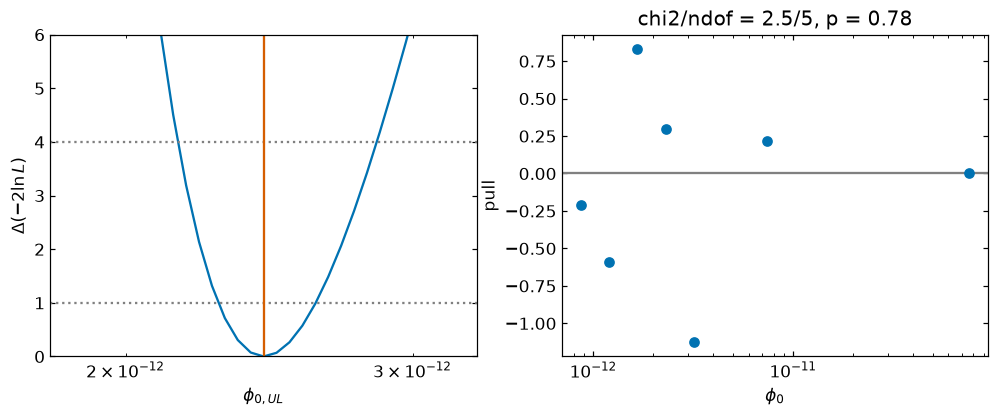

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(ul.profile["x"], ul.profile["delta_2nll"])
for lev in (1, 4):
    axs[0].axhline(lev, color="0.5", ls=":")
axs[0].axvline(ul.x_ul, color=COLORS[3])
axs[0].set_xscale("log")
axs[0].set_ylim(0, 6)
axs[0].set_xlabel(r"$\phi_{0,UL}$")
axs[0].set_ylabel(r"$\Delta(-2\ln L)$")
g = ul.gof
axs[1].axhline(0, color="0.5")
axs[1].plot(g["x"], g["pulls"], "o")
axs[1].set_xscale("log")
axs[1].set_xlabel(r"$\phi_0$")
axs[1].set_ylabel("pull")
axs[1].set_title(f"chi2/ndof = {g['chi2']:.1f}/{g['ndof']}, p = {g['pvalue']:.2f}")
figs.save(fig, "fit_diagnostics")
plt.show()

## Closure

The detection fraction of the independent sample at phi0_UL, its error (binomial and from the limit's
own uncertainty) and the pull with respect to CL.

300 realisations at phi0_UL: fraction above Lambda* = 0.947 +- 0.019 (binomial 0.013, from the UL 0.014); pull -0.18


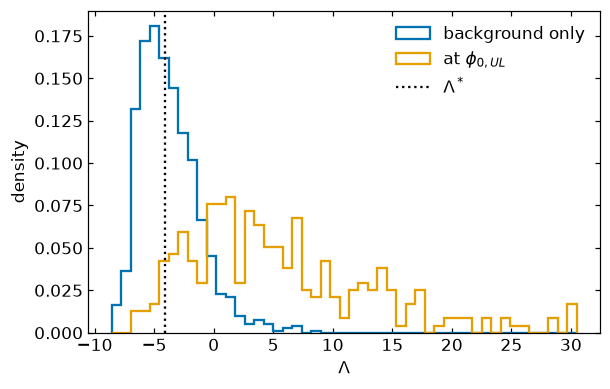

In [7]:
clo = res["closure"]
print(f"{clo['n']} realisations at phi0_UL: fraction above Lambda* = {clo['frac']:.3f} "
      f"+- {clo['err_tot']:.3f} (binomial {clo['err']:.3f}, from the UL {clo['err_ul']:.3f}); "
      f"pull {clo['pull']:+.2f}")
fig, ax = plt.subplots(figsize=(6, 3.8))
bins = np.linspace(min(det["lambda_bkg"].min(), det["lambda_closure"].min()),
                   np.percentile(det["lambda_closure"], 99), 50)
ax.hist(det["lambda_bkg"], bins=bins, histtype="step", lw=1.5, density=True, label="background only")
ax.hist(det["lambda_closure"], bins=bins, histtype="step", lw=1.5, density=True, label=r"at $\phi_{0,UL}$")
ax.axvline(ul.target, color="k", ls=":", label=r"$\Lambda^*$")
ax.set_xlabel(r"$\Lambda$")
ax.set_ylabel("density")
ax.legend()
figs.save(fig, "closure")
plt.show()

## Where the injected sources are detected

Detection fraction at the limit against the GW probability of the injected bin, from the closure
sample (single field: the bin is recorded by `PWLInjector2D`). Sources in low-probability bins need a
higher flux to beat Lambda*, which is why the global limit sits above the per-bin limit of the densest
bins. The open item of plan §3 (global UL vs the largest per-pixel UL in M95) needs the response tool
of study 3 and is not addressed here.

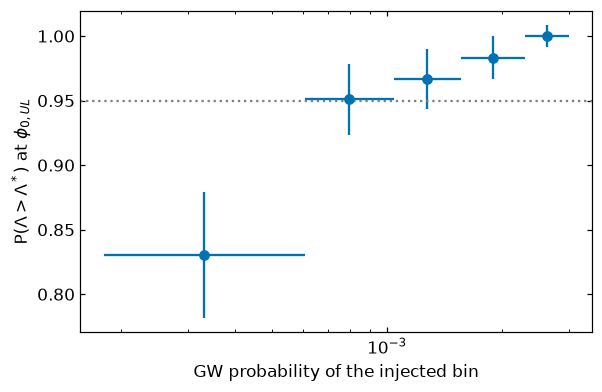

In [8]:
if res["n_fields"] == 1:
    out = realisations.run_fields(det["fields"], det["injector"], np.full(clo["n"], ul.x_ul),
                                  res["settings"]["seed"] + 3 * flux_ul.SEED_STRIDE, verbose=False)
    p_bin = det["fields"][0].gwmap.prob[out["iy"].astype(int), out["ix"].astype(int)]
    hit = out["lambda"] > ul.target
    edges = np.quantile(p_bin, np.linspace(0, 1, 6))
    idx = np.clip(np.searchsorted(edges, p_bin, side="right") - 1, 0, 4)
    n_j = np.array([(idx == j).sum() for j in range(5)])
    frac = np.array([hit[idx == j].mean() for j in range(5)])
    err = np.sqrt(np.maximum(frac * (1 - frac), 0.25 / n_j) / n_j)
    mid = np.sqrt(edges[:-1] * edges[1:])
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.errorbar(mid, frac, yerr=err, xerr=[mid - edges[:-1], edges[1:] - mid], fmt="o")
    ax.axhline(ul.cl, color="0.5", ls=":")
    ax.set_xscale("log")
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("GW probability of the injected bin")
    ax.set_ylabel(r"P($\Lambda > \Lambda^*$) at $\phi_{0,UL}$")
    figs.save(fig, "detection_vs_prob")
    plt.show()
else:
    print("several fields: the injected HEALPix pixel is recorded instead of a bin; skipped")

## Outputs

`outputs/results/1_flux_ul/<CASE>.json` (written by `flux_ul.flux_ul`), and figures in
`outputs/figures/1_flux_ul/4_flux_ul/`: `ul_fit`, `fit_diagnostics`, `closure`, `detection_vs_prob`.